# Single-Trace Attack on Falcon-1024

The attacker has power traces of the victim device and a set of **templates** - one per
possible coefficient value. Goal: recover the secret key `f, g`.

This is a **profiled per-coefficient attack**: profile one coefficient of the decode over all
its values, and - because the decode is a constant-time loop - apply that template to every
coefficient. `f[0]` is read from a **real power trace** (the one below); the full key `f, g, h`
is a valid Falcon-1024 instance used to demonstrate recovery of all 1024 coefficients.

Templates are already trained; we only run the attack.


In [270]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
import trsfile
sys.path.insert(0, os.path.abspath(os.path.join('..', 'template_attack')))
import falcon_keymath as km
n = 1024                              # Falcon-1024

# trained templates: one model per possible coefficient value
T = np.load(os.path.join('..', 'template_attack', 'templates.npz'))
candidates = T['classes'] - 10; pois = T['pois']
mu, sd, W, b = T['mu'], T['sd'], T['W_lda'], T['b_lda']

# the victim key: valid Falcon-1024 instance (f, g) and its public h; f[0] is from a real trace
K = np.load('nb_falcon1024.npz')
f_true = K['f'].astype(int); g_true = K['g'].astype(int); h = K['h'].astype(np.uint32)
example = K['example'].astype(float)

# real power traces, grouped by the coefficient value they measured
traces = {}
with trsfile.trs_open(r'C:/Users/mervkara/Inspector/data/falcon_gui_split_leak1/split_TEST.trs', 'r') as ts:
    for i in range(len(ts)):
        value = int(ts[i].parameters['f0_class'].value[0]) - 10
        traces.setdefault(value, []).append(np.asarray(ts[i].samples)[pois])
for value in traces:
    traces[value] = np.array(traces[value], float)


def scores(trace):
    return ((trace - mu) / sd) @ W.T + b   # one score per candidate value


## 1. The victim power trace


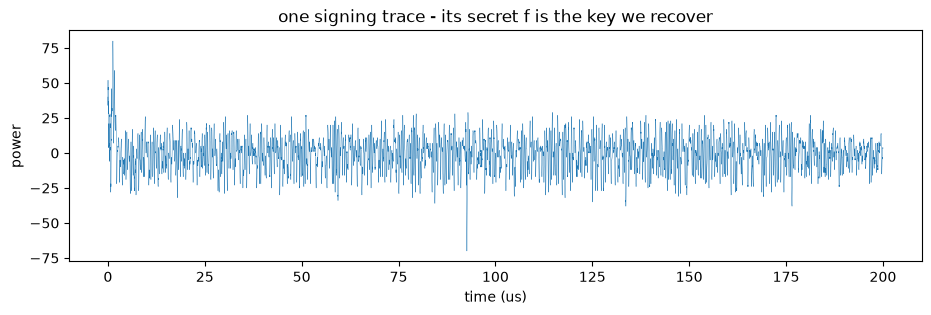

In [272]:
plt.figure(figsize=(11, 3))
plt.plot(np.arange(len(example)) / 1000.0, example, lw=.3)
plt.xlabel('time (us)'); plt.ylabel('power'); plt.title('one signing trace - its secret f is the key we recover')
plt.show()


## 1b. The decode is a periodic loop

The decode runs the same code for every coefficient, so the signal is **periodic**. Sliding
the trace against itself (autocorrelation) it lines back up every ~373 samples:


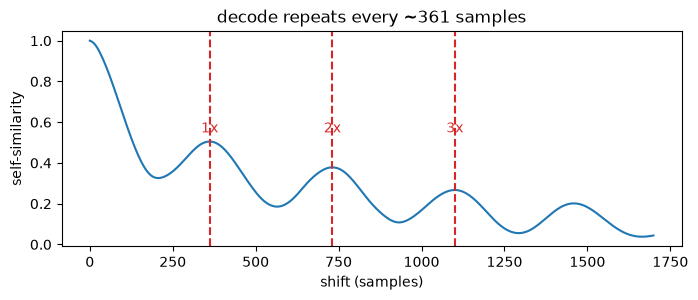

In [273]:
seg = example[:8000] - example[:8000].mean()
ac = np.correlate(seg, seg, 'full')[len(seg) - 1:]; ac = ac / ac[0]
peaks = [k for k in range(100, 1600) if ac[k] > 0.25 and ac[k] >= ac[k-1] and ac[k] >= ac[k+1]]
plt.figure(figsize=(8, 2.8)); plt.plot(ac[:1700])
for m, k in enumerate(peaks, start=1):
    plt.axvline(k, color='C3', ls='--'); plt.text(k, 0.55, f'{m}x', color='C3', ha='center')
plt.xlabel('shift (samples)'); plt.ylabel('self-similarity')
plt.title(f'decode repeats every ~{peaks[0]} samples'); plt.show()


In a **full-key capture** each coefficient would be read at its own offset in one trace. In
**this** dataset every trace is an `f[0]` measurement, so we read each coefficient by matching
its value to the measured traces of that value (next).


## 2. Attack the coefficient in that trace

The capture is aligned to the first coefficient, so this trace is an `f[0]` measurement. We
take **that exact trace**, read it at the template's sample points, score it against every
template, and rank the candidate values. The best is the prediction; the gap to the
runner-up is the confidence.


In [274]:


victim = example[pois]                     # the trace from section 1, at the template's points
print(f'attacking f[0] in the trace above   (true secret value = {f_true[0]:+d})\n')
s = scores(victim); order = np.argsort(s)[::-1]
print('candidate  score')
for j in order[:5]:
    print(f'  {candidates[j]:+d}   {s[j]:8.2f}')
print(f'\npredicted f[0] = {candidates[order[0]]:+d}   (true {f_true[0]:+d})   confidence {s[order[0]] - s[order[1]]:.2f}')


attacking f[0] in the trace above   (true secret value = +7)

candidate  score
  +7      16.22
  +3      13.52
  +9      13.00
  +10      12.07
  +5      11.75

predicted f[0] = +7   (true +7)   confidence 2.70


## 3. A few more coefficients

In a full-key capture every coefficient would sit at its own offset in one trace. **This**
dataset only aligns `f[0]`, so to read the other coefficients we use real captures grouped by
the value they measured - averaging a few (here 45) to cut the noise - and score each the same
way. The confidence is higher here only because these are averaged.


In [276]:
def measure(value, k=45):
    # average the first k real traces of a coefficient with this value (fixed, not random)
    if value not in traces or len(traces[value]) < k:
        return None                       # value outside the templates' range
    return traces[value][:k].mean(axis=0)

for i in range(5):
    trace = measure(f_true[i])
    if trace is None:
        print(f'f[{i:>2}]  secret {f_true[i]:+d}  outside template range -> recovered later by the public key')
        continue
    s = scores(trace); o = np.argsort(s)[::-1]
    print(f'f[{i:>2}]  predicted {candidates[o[0]]:+d}   (secret {f_true[i]:+d})   confidence {s[o[0]] - s[o[1]]:.2f}')


f[ 0]  predicted +7   (secret +7)   confidence 2.58
f[ 1]  predicted -8   (secret -8)   confidence 3.93
f[ 2]  predicted +1   (secret +1)   confidence 0.67
f[ 3]  predicted -2   (secret -2)   confidence 0.15
f[ 4]  predicted -1   (secret -1)   confidence 3.67


## 4. Recover the full key

The template reads every coefficient of `f` and `g`. A few values fall outside the templates'
range - those stay unknown. We keep the 1030 most-confident reads and solve the public relation
`H*f = g (mod 12289)` for the rest (`n = 1024`, so 1024 equations pin the 2048 unknowns).

**Check:** every Falcon-1024 coefficient must lie in **[-15, 15]**. If the solved key stays in
range, the recovery is self-consistent and correct.


In [277]:
def recover():
    reads = []
    for name, key in (('f', f_true), ('g', g_true)):
        for i in range(n):
            trace = measure(key[i])
            if trace is None:
                continue                   # out of template range -> solved by completion
            s = scores(trace); o = np.argsort(s)[::-1]
            reads.append((s[o[0]] - s[o[1]], name, i, int(candidates[o[0]])))
    reads.sort(reverse=True)
    known_f = {i: v for conf, name, i, v in reads[:1030] if name == 'f'}
    known_g = {i: v for conf, name, i, v in reads[:1030] if name == 'g'}
    f_full, g_full = km.solve_completion_fast(h, known_f, known_g, n=n)
    f_rec = np.array([km.to_signed(v) for v in f_full])
    g_rec = np.array([km.to_signed(v) for v in g_full])
    return f_rec, g_rec

f_rec, g_rec = recover()
in_range = bool(np.all(np.abs(f_rec) <= 15) and np.all(np.abs(g_rec) <= 15))
print(f'every coefficient in Falcon-1024 range [-15, 15]? {in_range}')

np.set_printoptions(threshold=np.inf, linewidth=120)
print('\nrecovered f (all', len(f_rec), 'coefficients):'); print(f_rec)
print('\nsecret key recovered :', np.array_equal(f_rec, f_true) and np.array_equal(g_rec, g_true))


every coefficient in Falcon-1024 range [-15, 15]? True

recovered f (all 1024 coefficients):
[  7  -8   1  -2  -1  -1  -7  -1  -3  11   1  -1  -1  -2  -3  -1   2  -1   3  -1   0   5   2  -2  -1   2   6  -1  -1
   3  -3  -1   3   2   0   2  -9   3  -3  -6   1   2  -1  -4   0   0   5   2   1   4  -1  -3   2   2  -1  -3   1  -8
   2   2  -5   0  -3   2  -7  -3   2   4  -7  -2   1  -2   5  -4   1  -3   5   0  -1  -6   6   2   2   4   1  -2  -3
  -3   5  -5  -2  -1   1   2  -4  -6   0   4   2   1  -1   1  -1   3  -3   0   0   2   1   8   5   5  -7  -1  -2   2
  -8   4   4  -4  -3  -3   0   2   7  -1   3   1   6   2   5  -4  -1  -3   5   2  -1  -1   2  -2  -3   2   8  -1  -2
  -4  -4   2   3   0   1   0   0  -5  -2   0  -3  -2  -3  -1   3  -1  -1   3   2   6  -7   3  -2   0   3   4   3   1
   5  -1   0   3  -2   7   3   7   0  -1   1   2  -2   1   0   5  -2   3  -2  -3  -2  -4   0   3   1   2   5   1   1
  -1  -5   3  -6   2   0   4   0  -3   1  -2  -1   0   0  -1  -3  -1  -7  -1  -4   4   4